# Importing Library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

import benchmarks
#import eli5
import itertools

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

import seaborn as sns
%matplotlib inline

import time
import random
from numpy.random import default_rng

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions
from xgboost import XGBClassifier
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

rng = np.random.default_rng(seed=42)
np.random.seed(42)

import warnings
warnings.filterwarnings("ignore")

import logging
logging.getLogger('joblib').setLevel(logging.WARNING)


In [2]:
# Load dataset
df = pd.read_csv("dataset_1.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [3]:
x=df[['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal']]
y=df['target']


# Feature Optimization

In [4]:
start_time = time.time()

In [5]:

class FireflyAlgorithm:
    def __init__(self, pop_size=20, alpha=1.0, betamin=1.0, gamma=0.01, seed=None):
        self.pop_size = pop_size
        self.alpha = alpha
        self.betamin = betamin
        self.gamma = gamma
        self.rng = default_rng(seed)

    def run(self, function, dim, lb, ub, max_evals):
        fireflies = self.rng.uniform(lb, ub, (self.pop_size, dim))
        intensity = np.apply_along_axis(function, 1, fireflies)
        best = np.min(intensity)

        evaluations = self.pop_size
        new_alpha = self.alpha
        search_range = ub - lb

        while evaluations <= max_evals:
            new_alpha *= 0.97
            for i in range(self.pop_size):
                for j in range(self.pop_size):
                    if intensity[i] >= intensity[j]:
                        r = np.sum(np.square(fireflies[i] - fireflies[j]), axis=-1)
                        beta = self.betamin * np.exp(-self.gamma * r)
                        steps = new_alpha * (self.rng.random(dim) - 0.5) * search_range
                        fireflies[i] += beta * (fireflies[j] - fireflies[i]) + steps
                        fireflies[i] = np.clip(fireflies[i], lb, ub)
                        intensity[i] = function(fireflies[i])
                        evaluations += 1
                        best = min(intensity[i], best)
        return best


In [6]:

Alpha=np.zeros(len(x.columns))

colneeded=[0,1,2,3,5,6,7,10,12]
#colneeded=[1,2,4,5,6,7,8,9,11,14,15,16,17,18,19,21,22,23]
modified_data=pd.DataFrame()
for i in colneeded:
    modified_data[x.columns[i]]=x[x.columns[i]].astype(float)
func_details=benchmarks.getFunctionDetails(6)

for i in range(0,len(x.columns)):
    #alpha=FireflyAlgorithm.run(function=getattr(benchmarks,'F7'), dim=30, lb=-5, ub=5, max_evals=1000)
    FA = FireflyAlgorithm()
    best = FA.run(getattr(benchmarks,'F6'), dim=len(x.columns), lb=-50, ub=50, max_evals=100)
    Alpha[i]=best




In [70]:
##Applying feature selection on the given dataset
##considering alpha as best solution and putting a threshold
threshold=5000
index=[]
print("alpha shape=",Alpha.shape[0])
modified_daata=pd.DataFrame();
for i in range(0,Alpha.shape[0]):
    if(Alpha[i]>=threshold):
        modified_daata[x.columns[i]]=x[x.columns[i]].astype(float)
print("The modified data is following")
modified_daata.head()

alpha shape= 13
The modified data is following


,age,sex,cp,chol,fbs,restecg,exang,oldpeak,ca,thal
0,63.0,1.0,1.0,233.0,1.0,2.0,0.0,2.3,0.0,6.0
1,67.0,1.0,4.0,286.0,0.0,2.0,1.0,1.5,3.0,3.0
2,67.0,1.0,4.0,229.0,0.0,2.0,1.0,2.6,2.0,7.0
3,37.0,1.0,3.0,250.0,0.0,0.0,0.0,3.5,0.0,3.0
4,41.0,0.0,2.0,204.0,0.0,2.0,0.0,1.4,0.0,3.0


In [69]:
Alpha

array([5867.42846788, 7435.51394666, 6929.6826714 , 2027.95836818,
       5970.83192949, 6509.56035055, 5582.78263028, 4080.68684006,
       5166.24133118, 6720.3363755 , 4980.47562632, 5692.70926908,
       5421.16098733])

In [71]:
xf=modified_daata
xf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   age      297 non-null    float64
 1   sex      297 non-null    float64
 2   cp       297 non-null    float64
 3   chol     297 non-null    float64
 4   fbs      297 non-null    float64
 5   restecg  297 non-null    float64
 6   exang    297 non-null    float64
 7   oldpeak  297 non-null    float64
 8   ca       297 non-null    float64
 9   thal     297 non-null    float64
dtypes: float64(10)
memory usage: 23.3 KB


In [72]:
def GWO(objf,lb,ub,dim,SearchAgents_no,Max_iter):
    
    # initialize alpha, beta, and delta_pos
    Alpha_pos=np.zeros(dim)
    Alpha_score=float("inf")
    
    Beta_pos=np.zeros(dim)
    Beta_score=float("inf")
    
    Delta_pos=np.zeros(dim)
    Delta_score=float("inf")

    if not isinstance(lb, list):
        lb = [lb] * dim
    if not isinstance(ub, list):
        ub = [ub] * dim
    
    #Initialize the positions of search agents
    Positions = np.zeros((SearchAgents_no, dim))
    for i in range(dim):
        Positions[:, i] = np.random.RandomState(42).uniform(0,1, SearchAgents_no) * (ub[i] - lb[i]) + lb[i]
    
    Convergence_curve=np.zeros(Max_iter)

     # Loop counter
    print("GWO is optimizing  \""+objf.__name__+"\"")    

    # Main loop
    for l in range(0,Max_iter):
        for i in range(0,SearchAgents_no):
            
            # Return back the search agents that go beyond the boundaries of the search space
            for j in range(dim):
                Positions[i,j]=np.clip(Positions[i,j], lb[j], ub[j])

            # Calculate objective function for each search agent
            fitness=objf(Positions[i,:])
            
            # Update Alpha, Beta, and Delta
            if fitness<Alpha_score :
                Alpha_score=fitness; # Update alpha
                Alpha_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness<Beta_score ):
                Beta_score=fitness  # Update beta
                Beta_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness>Beta_score and fitness<Delta_score): 
                Delta_score=fitness # Update delta
                Delta_pos=Positions[i,:].copy()
        
        a=2-l*((2)/Max_iter); # a decreases linearly fron 2 to 0
        
        # Update the Position of search agents including omegas
        for i in range(0,SearchAgents_no):
            for j in range (0,dim):     
                           
                r1=random.random() # r1 is a random number in [0,1]
                r2=random.random() # r2 is a random number in [0,1]
                
                A1=2*a*r1-a; # Equation (3.3)
                C1=2*r2; # Equation (3.4)
                
                D_alpha=abs(C1*Alpha_pos[j]-Positions[i,j]); # Equation (3.5)-part 1
                X1=Alpha_pos[j]-A1*D_alpha; # Equation (3.6)-part 1
                           
                r1=random.random()
                r2=random.random()
                
                A2=2*a*r1-a; # Equation (3.3)
                C2=2*r2; # Equation (3.4)
                
                D_beta=abs(C2*Beta_pos[j]-Positions[i,j]); # Equation (3.5)-part 2
                X2=Beta_pos[j]-A2*D_beta; # Equation (3.6)-part 2       
                
                r1=random.random()
                r2=random.random() 
                
                A3=2*a*r1-a; # Equation (3.3)
                C3=2*r2; # Equation (3.4)
                
                D_delta=abs(C3*Delta_pos[j]-Positions[i,j]); # Equation (3.5)-part 3
                X3=Delta_pos[j]-A3*D_delta; # Equation (3.5)-part 3             
                
                Positions[i,j]=(X1+X2+X3)/3  # Equation (3.7)        
        Convergence_curve[l]=Alpha_score;

        #if (l%1==0):
               #print(['At iteration '+ str(l)+ ' the best fitness is '+ str(Alpha_score)]);
    
    print(Positions.shape)
    print("Alpha position=",Alpha_pos);
    print("Beta position=",Beta_pos);
    print("Delta position=",Delta_pos);
    return Alpha_pos,Beta_pos;

In [73]:

iters=200
wolves=2*len(xf.columns)
dimension=len(xf.columns)
search_domain=[0,1]
lb=-50
ub=50
colneeded=[0,1,2,3,5,6,7,8,9]
#colneeded=[1,2,4,5,6,7,8,9,11,14,15,16,17,18,19,21,22,23,24,25,26,28,29]
modified_data=pd.DataFrame()
for i in colneeded:
    modified_data[xf.columns[i]]=xf[xf.columns[i]].astype(float)
func_details=benchmarks.getFunctionDetails(7)

for i in range(0,dimension-1):
    alpha,beta=GWO(getattr(benchmarks,'F7'),lb,ub,dimension,wolves,iters)
    


GWO is optimizing  "F7"
(20, 10)
Alpha position= [ 4.38301074e-05  4.02092154e-05  1.12743549e-06  2.86802188e-05
 -3.51988469e-05 -1.90819625e-05  1.72615970e-05  3.12085852e-05
 -7.82522290e-07  1.93750172e-05]
Beta position= [ 4.45172471e-05  6.07938136e-05 -5.53130944e-05  4.40856666e-05
 -2.10235445e-05 -4.02970149e-05  1.59601747e-05  3.81565077e-05
 -2.16733003e-07  1.03122322e-05]
Delta position= [ 4.83512274e-05  6.33432962e-05 -6.85983517e-05  3.55912469e-05
 -2.75346335e-05 -4.36409505e-05  2.23093355e-05  5.63002352e-05
 -1.57829036e-06  1.01511534e-05]
GWO is optimizing  "F7"
(20, 10)
Alpha position= [-1.45357041e-05 -5.10351240e-05  7.48892910e-06 -4.13062368e-07
  1.33299395e-05  3.09028159e-05 -1.65350283e-05 -1.42970625e-05
 -1.27803233e-05 -3.16776363e-05]
Beta position= [-5.06411221e-05 -6.49153569e-05  6.39689013e-06 -2.51492459e-06
  3.83793448e-05  1.81477272e-05  1.16869068e-05 -3.39739606e-05
 -2.06207849e-05 -4.89830226e-05]
Delta position= [-4.23213654e-05 -3.

In [74]:
##Applying feature selection on the given dataset
##considering alpha as best solution and putting a threshold
threshold=-2e-05
index=[]
print("alpha shape=",alpha.shape[0])
modified_daata=pd.DataFrame();
for i in range(0,alpha.shape[0]):
    if(alpha[i]>=threshold):
        modified_daata[xf.columns[i]]=xf[xf.columns[i]].astype(float)
print("The modified data is following")
modified_daata.head()

alpha shape= 10
The modified data is following


,cp,chol,fbs,restecg,exang,oldpeak,ca,thal
0,1.0,233.0,1.0,2.0,0.0,2.3,0.0,6.0
1,4.0,286.0,0.0,2.0,1.0,1.5,3.0,3.0
2,4.0,229.0,0.0,2.0,1.0,2.6,2.0,7.0
3,3.0,250.0,0.0,0.0,0.0,3.5,0.0,3.0
4,2.0,204.0,0.0,2.0,0.0,1.4,0.0,3.0


In [75]:
alpha

array([-3.45749719e-05, -5.01501198e-05,  3.50197920e-05,  2.98043655e-05,
       -1.68853681e-05,  2.62479641e-05,  2.25282114e-06,  1.93535365e-05,
        9.03130518e-06, -1.88229629e-06])

In [76]:
xfg=modified_daata
xfg.info()
xfg.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cp       297 non-null    float64
 1   chol     297 non-null    float64
 2   fbs      297 non-null    float64
 3   restecg  297 non-null    float64
 4   exang    297 non-null    float64
 5   oldpeak  297 non-null    float64
 6   ca       297 non-null    float64
 7   thal     297 non-null    float64
dtypes: float64(8)
memory usage: 18.7 KB


Index(['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal'], dtype='object')

In [77]:
end_time = time.time()
runtime = end_time - start_time

In [78]:
print(f"Simulation Runtime:{runtime:.2f} seconds")

Simulation Runtime:2580.98 seconds


# Feature Defining 

In [28]:
x.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')

In [87]:
xf.columns

Index(['age', 'sex', 'cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca',
       'thal'],
      dtype='object')

In [80]:
xfg.columns

Index(['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal'], dtype='object')

In [ ]:
#xg2=x[['Age at Diagnosis', 'Cohort', 'ER status measured by IHC', 'ER Status']]

In [81]:
# Split into train and test sets
from sklearn.metrics import confusion_matrix
n=0
m=0.20

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=m, random_state=n)
xf_train, xf_test, y_train, y_test = train_test_split(xf, y, test_size=m, random_state=n)
#xg_train, xg_test, y_train, y_test = train_test_split(xg, y, test_size=m, random_state=n)
xfg_train, xfg_test, y_train, y_test = train_test_split(xfg, y, test_size=m, random_state=n)

kfold = KFold(n_splits=10, shuffle=True, random_state=n) 

In [ ]:
x.info()

In [ ]:
xfg.info()

In [ ]:
#from sklearn.metrics import confusion_matrix
#n=0
#m=0.20

#x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=m, random_state=n)
#xf_train, xf_test, y_train, y_test = train_test_split(xf, y, test_size=m, random_state=n)
#xfg_train, xfg_test, y_train, y_test = train_test_split(xfg, y, test_size=m, random_state=n)

# All Feature

In [33]:
#clf=DecisionTreeClassifier(criterion='entropy',max_depth=8,max_leaf_nodes=8,random_state=0)
#clf=DecisionTreeClassifier(criterion='log_loss',max_depth=3,max_leaf_nodes=3,random_state=None)
#entropy
#clf = MLPClassifier(hidden_layer_sizes=(50, 50, 50), activation="relu", learning_rate="constant",max_iter=100)
#clf = XGBClassifier(verbosity=2,bool=True,max_depth=100)
#clf = RandomForestClassifier()
#clf = LogisticRegression()

#---
from sklearn.ensemble import VotingClassifier

clf1 = LogisticRegression()
clf1.fit(x_train, y_train)

clf2 = RandomForestClassifier()
clf2.fit(x_train, y_train)

clf3 = DecisionTreeClassifier()
clf3.fit(x_train, y_train)


models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
#    prob = model.predict_proba(x_test)[:, 1]
    acc = accuracy_score(y_test, pred)
#    auc = roc_auc_score(y_test, prob)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"{name} -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")
 


LR -> Accuracy: 0.8167, Confusion Matrix: [27 3 8 22]
RF -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
xGB -> Accuracy: 0.7500, Confusion Matrix: [21 9 6 24]
DT -> Accuracy: 0.7500, Confusion Matrix: [21 9 6 24]
MLP -> Accuracy: 0.7500, Confusion Matrix: [26 4 11 19]
SVC -> Accuracy: 0.7500, Confusion Matrix: [23 7 8 22]
HVC -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]


In [ ]:
print("\033[1mAll feature, Cross Validation\033[0m")


clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = DecisionTreeClassifier()


models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(n_estimators=200),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

for name, model in models.items():
    #model.fit(x_train, y_train)
    pred = cross_val_predict(model, x, y, cv=kfold)
    #pred = model.predict(x_test)
    acc = accuracy_score(y, pred)    
    prec = precision_score(y, pred,average='weighted')
    rec = recall_score(y, pred,average='weighted')
    f1 = f1_score(y, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")
    
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    table = [[tp + tn, fp], [fn, 0]]
    result = mcnemar(table, exact=True)
    p_value = result.pvalue
    
    print(f"p-value (McNemar Test): {p_value:.6f}") 
    
    if p_value < 0.05:
        print("=> The result is statistically significant (p < 0.05).")
    else:
        print("=> The result is not statistically significant (p ≥ 0.05).")


# FA

In [82]:
clf1 = LogisticRegression(max_iter=50)
clf1.fit(xf_train, y_train)

clf2 = RandomForestClassifier(n_estimators=2)
clf2.fit(xf_train, y_train)

clf3 = DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=2)
clf3.fit(xf_train, y_train)

models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(n_estimators=5),
    "xGB": XGBClassifier(n_estimators=2),
    "DT": DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=2),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xf_train, y_train)
    pred = model.predict(xf_test)
#    prob = model.predict_proba(xfg_test)[:, 1]
    acc = accuracy_score(y_test, pred)
#    auc = roc_auc_score(y_test, prob)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"{name} -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")

LR -> Accuracy: 0.8167, Confusion Matrix: [26 4 7 23]
RF -> Accuracy: 0.6500, Confusion Matrix: [21 9 12 18]
xGB -> Accuracy: 0.7500, Confusion Matrix: [23 7 8 22]
DT -> Accuracy: 0.6833, Confusion Matrix: [28 2 17 13]
MLP -> Accuracy: 0.8500, Confusion Matrix: [26 4 5 25]
SVC -> Accuracy: 0.8000, Confusion Matrix: [25 5 7 23]
HVC -> Accuracy: 0.7500, Confusion Matrix: [28 2 13 17]


In [ ]:
print("\033[1mFirefly, Cross Validation\033[0m")


clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = DecisionTreeClassifier()


models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(n_estimators=200),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

for name, model in models.items():
    #model.fit(x_train, y_train)
    pred = cross_val_predict(model, x, y, cv=kfold)
    #pred = model.predict(x_test)
    acc = accuracy_score(y, pred)    
    prec = precision_score(y, pred,average='weighted')
    rec = recall_score(y, pred,average='weighted')
    f1 = f1_score(y, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")
    
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    table = [[tp + tn, fp], [fn, 0]]
    result = mcnemar(table, exact=True)
    p_value = result.pvalue
    
    print(f"p-value (McNemar Test): {p_value:.6f}") 
    
    if p_value < 0.05:
        print("=> The result is statistically significant (p < 0.05).")
    else:
        print("=> The result is not statistically significant (p ≥ 0.05).")


# GW

In [ ]:
clf1 = LogisticRegression(max_iter=50)
clf1.fit(xg_train, y_train)

clf2 = RandomForestClassifier(n_estimators=3)
clf2.fit(xg_train, y_train)

clf3 = DecisionTreeClassifier(criterion='log_loss',splitter='best',max_depth=2)
clf3.fit(xg_train, y_train)

models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard',weights=[0,0,1]),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xg_train, y_train)
    pred = model.predict(xg_test)
#    prob = model.predict_proba(xfg_test)[:, 1]
    acc = accuracy_score(y_test, pred)
#    auc = roc_auc_score(y_test, prob)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"{name} -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")

# FGO

In [99]:
clf1 = LogisticRegression(max_iter=300)
clf1.fit(x_train, y_train)

clf2 = RandomForestClassifier(criterion='gini',max_depth=200,verbose=0)
clf2.fit(x_train, y_train)

clf3 = DecisionTreeClassifier(criterion='gini',max_depth=12,max_leaf_nodes=10)
clf3.fit(x_train, y_train)

models = {
    "LR": LogisticRegression(max_iter=300),
    "RF": RandomForestClassifier(max_depth=300,verbose=0),
    "xGB": XGBClassifier(n_estimators=100,learning_rate=0.05,max_depth=4,verbosity=0,
    eval_metric="logloss"),
    "DT": DecisionTreeClassifier(criterion='gini',max_depth=5,max_leaf_nodes=7,splitter='best',random_state=i,min_impurity_decrease=0.0),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,100,100) ,activation='relu',max_iter=300, random_state=20),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft',weights=[2,3,1]),
    #"SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft',weights=[2,3,2]),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xfg_train, y_train)
    pred = model.predict(xfg_test)
#    prob = model.predict_proba(xfg_test)[:, 1]
    acc = accuracy_score(y_test, pred)
#    auc = roc_auc_score(y_test, prob)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"{name} -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")

LR -> Accuracy: 0.5833, Confusion Matrix: [22 10 15 13]
RF -> Accuracy: 0.4333, Confusion Matrix: [16 16 18 10]
xGB -> Accuracy: 0.5000, Confusion Matrix: [19 13 17 11]
DT -> Accuracy: 0.5333, Confusion Matrix: [17 15 13 15]
MLP -> Accuracy: 0.5500, Confusion Matrix: [32 0 27 1]
SVC -> Accuracy: 0.5333, Confusion Matrix: [20 12 16 12]
HVC -> Accuracy: 0.5667, Confusion Matrix: [17 15 11 17]


In [ ]:
print("\033[1mFGO, Cross Validation\033[0m")


clf1 = LogisticRegression(max_iter=300,solver='liblinear',fit_intercept=True,verbose=1)
clf2 = RandomForestClassifier(criterion='gini',max_depth=200,verbose=1)
clf3 = DecisionTreeClassifier(criterion='gini',max_depth=12,max_leaf_nodes=10)

models = {
    "LR": LogisticRegression(max_iter=300,solver='liblinear',fit_intercept=True,verbose=0),
    #"LR": LogisticRegression(max_iter=300),
    "RF": RandomForestClassifier(criterion='gini',max_depth=200,verbose=0),
    "xGB": XGBClassifier(n_estimators=100),
    "DT": DecisionTreeClassifier(criterion='gini',max_depth=12,max_leaf_nodes=10),
    "MLP": MLPClassifier(hidden_layer_sizes=(100) ,activation='relu',max_iter=300, random_state=20),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft',weights=[2,3,2]),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

for name, model in models.items():
    #model.fit(x_train, y_train)
    pred = cross_val_predict(model, xfg, y, cv=kfold)
    #pred = model.predict(x_test)
    acc = accuracy_score(y, pred)    
    prec = precision_score(y, pred,average='weighted')
    rec = recall_score(y, pred,average='weighted')
    f1 = f1_score(y, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")
    
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    table = [[tp + tn, fp], [fn, 0]]
    result = mcnemar(table, exact=True)
    p_value = result.pvalue
    
    print(f"p-value (McNemar Test): {p_value:.6f}") 
    
    if p_value < 0.05:
        print("=> The result is statistically significant (p < 0.05).")
    else:
        print("=> The result is not statistically significant (p ≥ 0.05).")


# Results with ROC

In [36]:
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import VotingClassifier
clf1 = LogisticRegression(solver='lbfgs',max_iter=100,verbose=3)
clf2 = RandomForestClassifier()
clf3 = DecisionTreeClassifier(criterion='gini',max_depth=8,max_leaf_nodes=7,random_state=40)
#clf = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft')
#clf = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard')


models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    #"HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xfg_train, y_train)
    pred = model.predict(xfg_test)
    prob = model.predict_proba(xfg_test)[:, 1]
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)
    print(f"{name} -> Accuracy: {acc:.4f}, ROC AUC: {auc:.4f}")

LR -> Accuracy: 0.8333, ROC AUC: 0.9133
RF -> Accuracy: 0.8000, ROC AUC: 0.8811
xGB -> Accuracy: 0.7500, ROC AUC: 0.8478
DT -> Accuracy: 0.7167, ROC AUC: 0.7167
MLP -> Accuracy: 0.8000, ROC AUC: 0.9056


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


SVC -> Accuracy: 0.8167, ROC AUC: 0.8956


# LR  Feature Importance

All Feature
Accuracy All: 0.8166666666666667
     Feature  Importance
11        ca    1.004086
8      exang    0.850200
1        sex    0.610071
2         cp    0.469163
12      thal    0.392102
9    oldpeak    0.290077
5        fbs    0.275153
6    restecg    0.176265
10     slope    0.119716
7    thalach    0.045094
0        age    0.043126
3   trestbps    0.023088
4       chol    0.003117


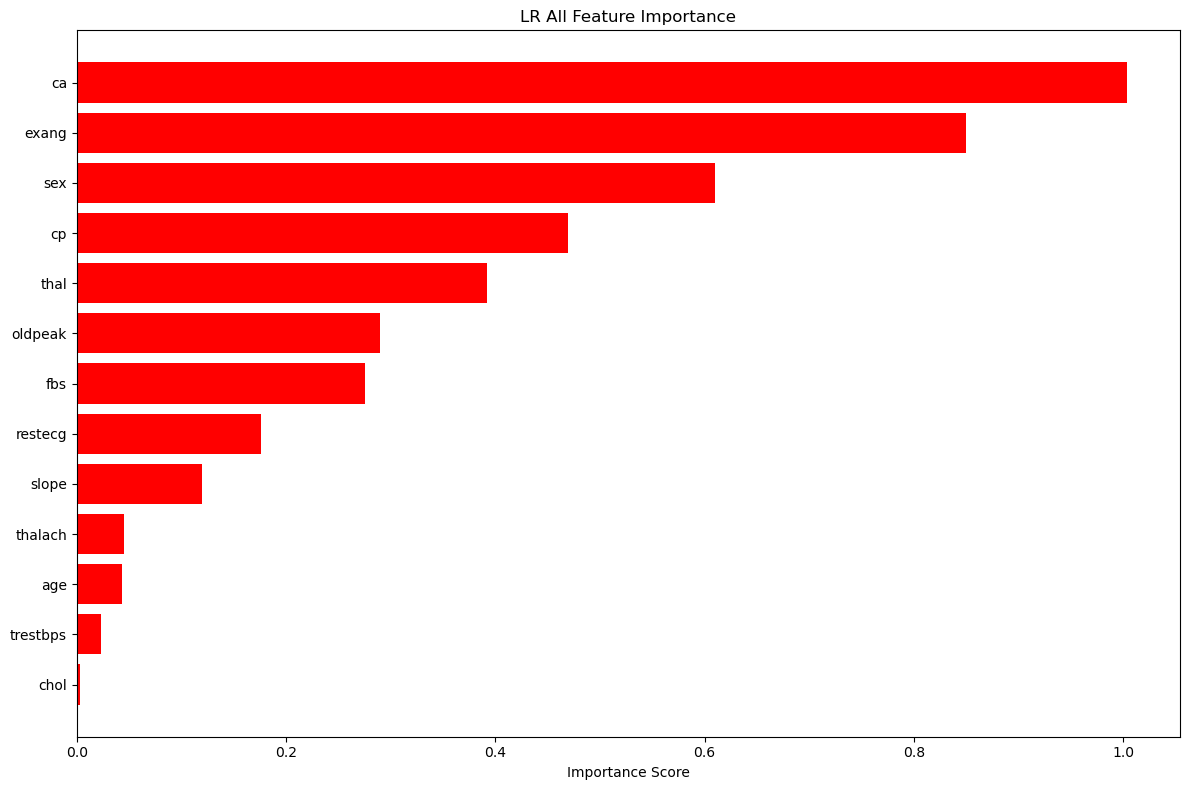

FGO
Accuracy FGO: 0.8333333333333334
   Feature  Importance
3    exang    1.267795
6       ca    0.932643
0      sex    0.467440
1      fbs    0.456665
7     thal    0.442994
4  oldpeak    0.290052
5    slope    0.281535
2  thalach    0.024991


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


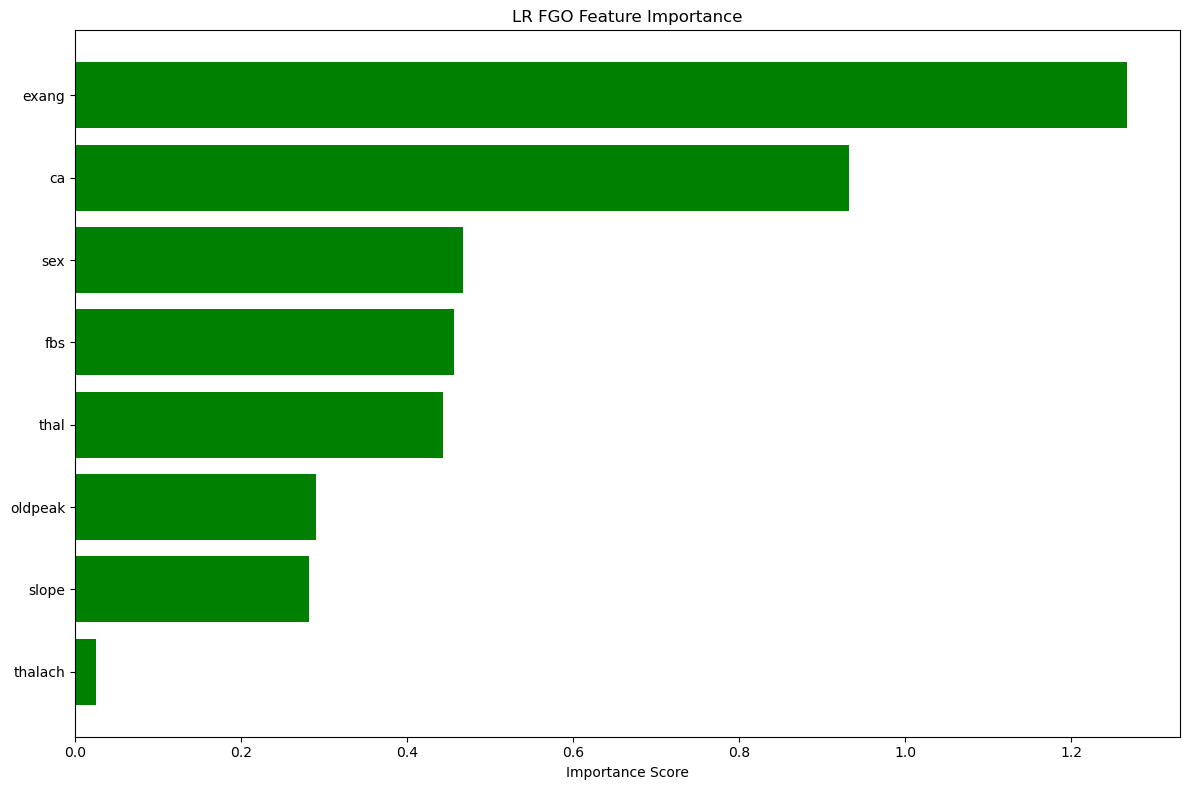

In [37]:
print("All Feature")

# Train model
clf = LogisticRegression()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[92mAccuracy All:\033[0m", accuracy_score(y_test, y_pred))

# Get feature importance (absolute value of coefficients)
importance = abs(clf.coef_[0])  # shape: (n_features,)

# Combine with feature names
feature_importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

# Plot
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='red')
plt.xlabel('Importance Score')
plt.title('LR All Feature Importance')
plt.gca().invert_yaxis()  # Most important at the top
plt.tight_layout()
plt.show()


print("FGO")

# Train model
clf = LogisticRegression(solver='lbfgs',max_iter=100,verbose=3)
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))

# Get feature importance (absolute value of coefficients)
importance = abs(clf.coef_[0])  # shape: (n_features,)

# Combine with feature names
feature_importance = pd.DataFrame({
    'Feature': xfg.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

# Plot
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='green')
plt.xlabel('Importance Score')
plt.title('LR FGO Feature Importance')
plt.gca().invert_yaxis()  # Most important at the top
plt.tight_layout()
plt.show()

# RF Feature Importance

Accuracy All feature: 0.7833333333333333


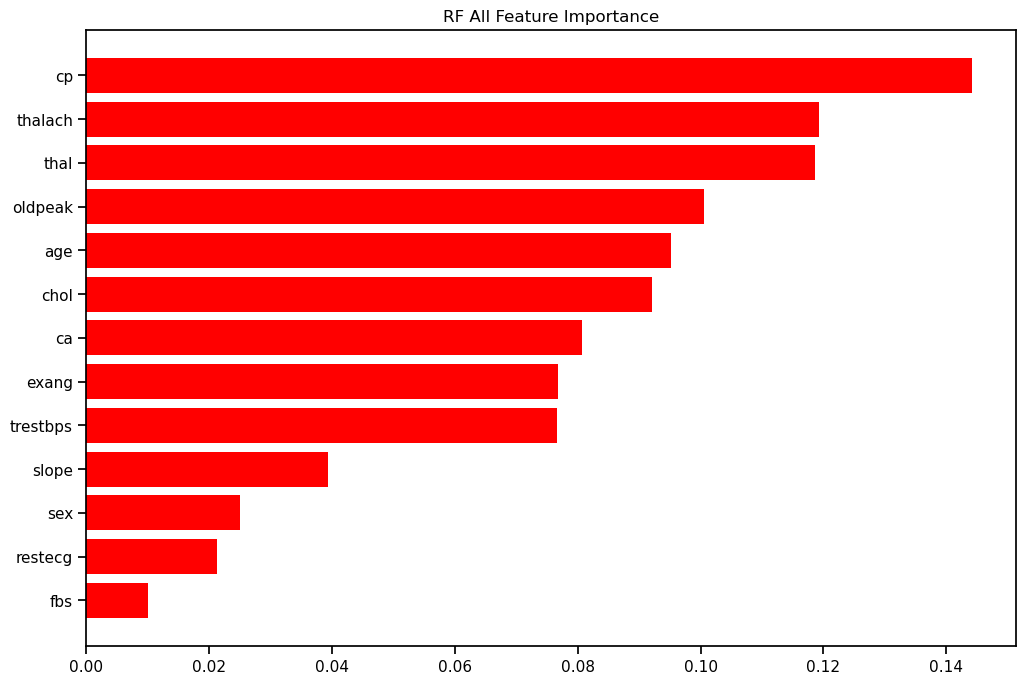

In [38]:

# Train model
clf = RandomForestClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[91mAccuracy All feature:\033[0m", accuracy_score(y_test, y_pred))
#print("Classification Report:\n", classification_report(y_test, y_pred))

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
plt.title('RF All Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='red')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x_train.columns)[indices])

Accuracy FGO: 0.7833333333333333


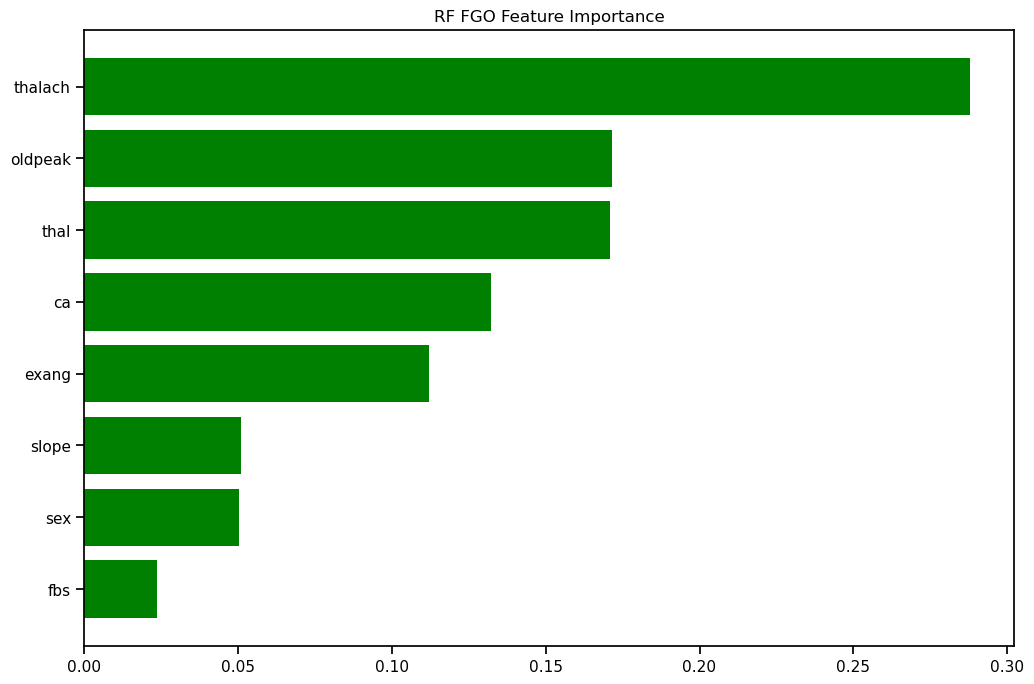

In [39]:

# Train model
clf = RandomForestClassifier(max_depth=16)
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[91mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))
#print("Classification Report:\n", classification_report(y_test, y_pred))

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
plt.title('RF FGO Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='green')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(xfg_train.columns)[indices])

# DT Feature Importance

Accuracy All: 0.7166666666666667


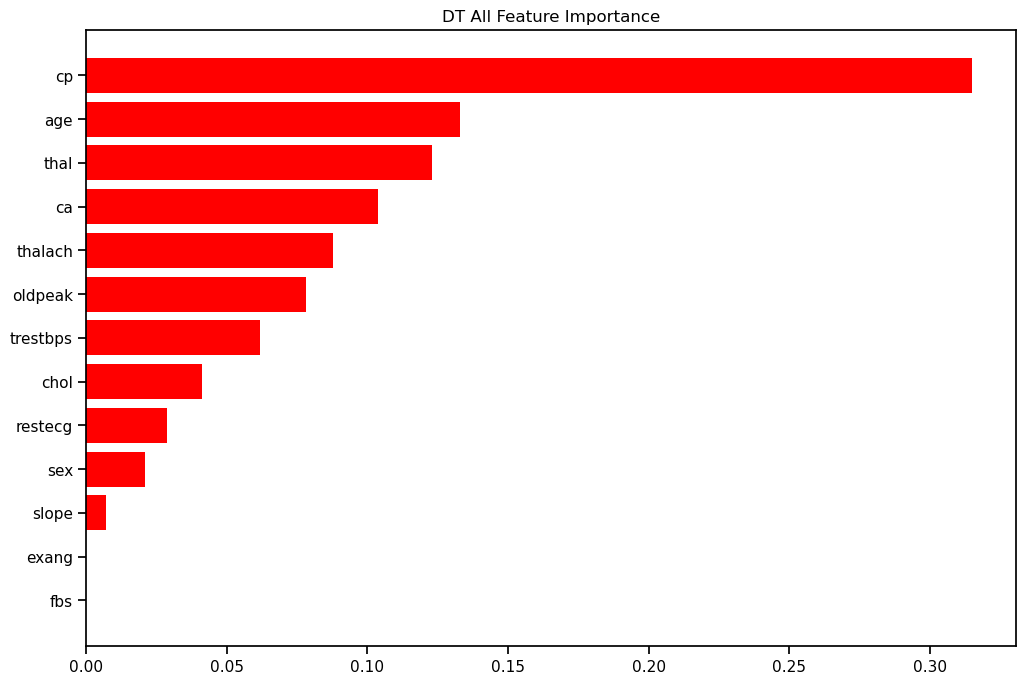

In [44]:
# Train model
clf = DecisionTreeClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[92mAccuracy All:\033[0m", accuracy_score(y_test, y_pred))


importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
plt.title('DT All Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='red')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x_train.columns)[indices])

Accuracy FGO: 0.7833333333333333


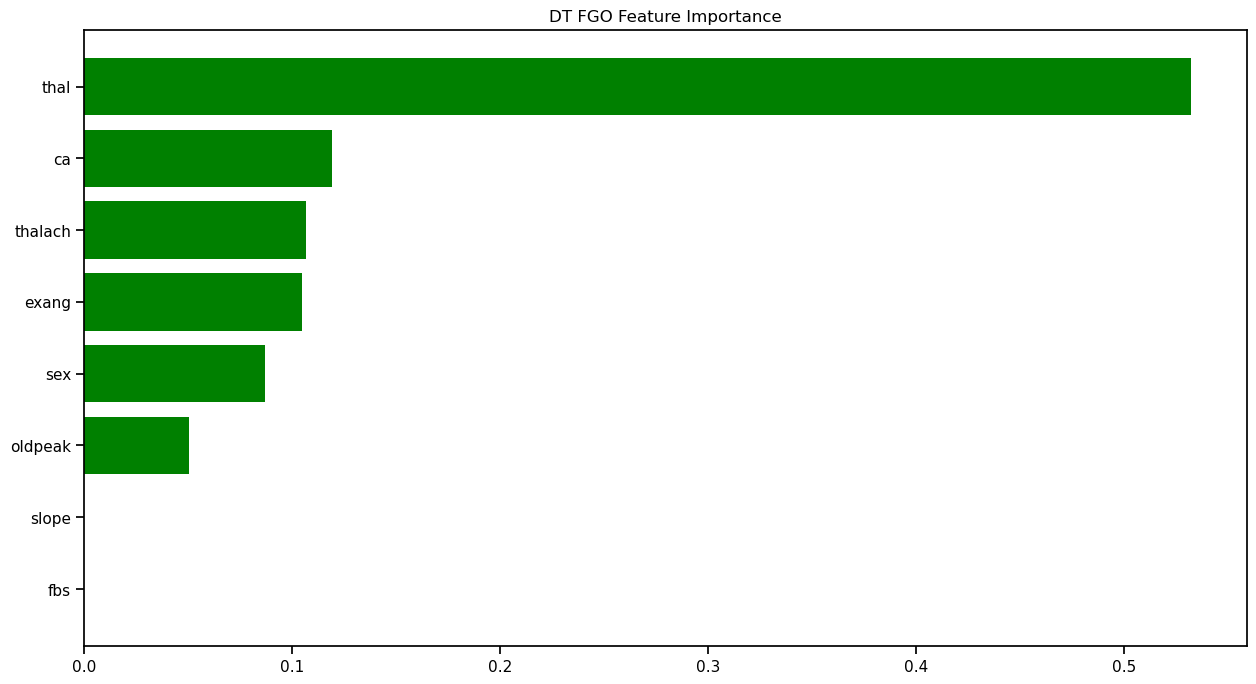

In [45]:
# Train model
clf = DecisionTreeClassifier(criterion='gini',max_depth=8,max_leaf_nodes=7)
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))


importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(15, 8))
plt.title('DT FGO Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='green')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(xfg_train.columns)[indices])

# xGB Feature Importance

Accuracy All: 0.75


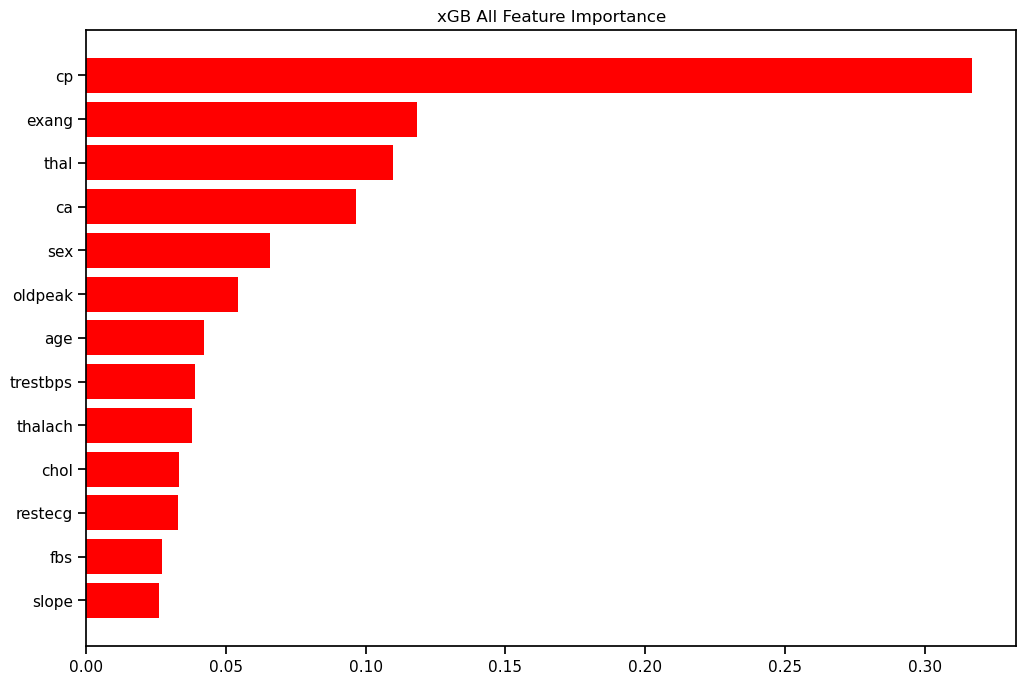

In [46]:
# Train model
clf = XGBClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[92mAccuracy All:\033[0m", accuracy_score(y_test, y_pred))


importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
plt.title('xGB All Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='red')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x_train.columns)[indices])

Accuracy FGO: 0.7666666666666667


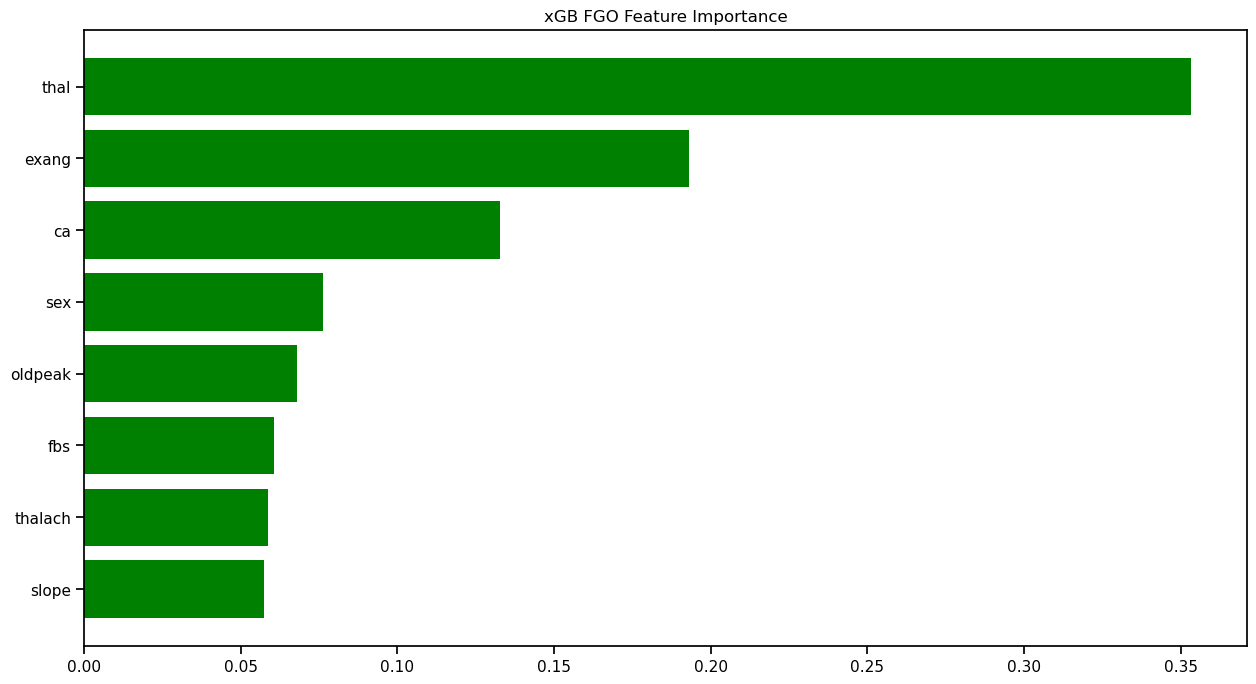

In [47]:
# Train model
clf = XGBClassifier(n_estimators=300 ,learning_rate=0.05,max_depth=100,verbosity=0,eval_metric="logloss")
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))


importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(15, 8))
plt.title('xGB FGO Feature Importance')
ax.barh(range(len(importances)), importances[indices],color='green')
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(xfg_train.columns)[indices])

# Individual results 

In [49]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

A = [1,5,10,20,50,60,70,80,90,100,200]


for i in A:
    model = XGBClassifier(n_estimators=i,learning_rate=0.05,max_depth=4,verbosity=0,
    eval_metric="logloss")
    model.fit(xfg_train, y_train)
    pred = model.predict(xfg_test)
    acc = accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"XGB (n_estimators={i}) -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")


XGB (n_estimators=1) -> Accuracy: 0.5000, Confusion Matrix: [30 0 30 0]
XGB (n_estimators=5) -> Accuracy: 0.7667, Confusion Matrix: [26 4 10 20]
XGB (n_estimators=10) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=20) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=50) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=60) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=70) -> Accuracy: 0.8000, Confusion Matrix: [26 4 8 22]
XGB (n_estimators=80) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=90) -> Accuracy: 0.7833, Confusion Matrix: [26 4 9 21]
XGB (n_estimators=100) -> Accuracy: 0.8000, Confusion Matrix: [27 3 9 21]
XGB (n_estimators=200) -> Accuracy: 0.7667, Confusion Matrix: [26 4 10 20]


In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

A = [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,40,50,100,60,70,80,90]

for depth in A:   # loop over values of max_depth
    model = DecisionTreeClassifier(criterion='gini',max_depth=5,max_leaf_nodes=7,splitter='best',random_state=i,min_impurity_decrease=0.0)
    model.fit(xfg_train, y_train)
    pred = model.predict(xfg_test)
    acc = accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred).ravel()
    cm_str = ' '.join(map(str, cm))
    print(f"RF(max_depth={depth}) -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")


RF(max_depth=0) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=1) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=2) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=3) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=4) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=5) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=6) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=7) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=8) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=9) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=10) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=11) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=12) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=13) -> Accuracy: 0.7833, Confusion Matrix: [27 3 10 20]
RF(max_depth=14) -> Accuracy: 0.7833, Confus

In [ ]:
c=classification_report(y_test, pred)
print(c)

In [93]:
# === Heart Disease Classification with 5 ML Models ===
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import numpy as np

# === Load UCI Heart Disease dataset (Cleveland) ===
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
col_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
             "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(url, names=col_names)

# Replace missing values ("?") with NaN and drop rows with missing data
df.replace('?', np.nan, inplace=True)
df = df.dropna()

# Convert columns to numeric
df = df.apply(pd.to_numeric)

# Convert target >0 as 1 (heart disease present)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

# === Split features and target ===
X = df.drop('target', axis=1)
y = df['target']

Xf=df[['age', 'sex', 'cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca','thal']]
Xfg=df[['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]


# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
Xf_scaled = scaler.fit_transform(Xf)
Xfg_scaled = scaler.fit_transform(Xfg)



# === Split dataset ===
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=0, stratify=y)
Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf_scaled, y, test_size=0.2, random_state=0, stratify=y)
Xfg_train, Xfg_test, yfg_train, yfg_test = train_test_split(Xfg_scaled, y, test_size=0.2, random_state=0, stratify=y)

# === Initialize models ===
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=0)
}

# === Train and evaluate ===
accuracy_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracy_results[name] = round(acc * 100, 2)

# === Show results ===
print("Accuracy Results (All feature):")
for k, v in accuracy_results.items():
    print(f"{k:20s}: {v}%")
    
    

# === Initialize models ===
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=0)
}

# === Train and evaluate ===
accuracy_results = {}
for name, model in models.items():
    model.fit(Xf_train, yf_train)
    y_pred = model.predict(Xf_test)
    acc = accuracy_score(yf_test, y_pred)
    accuracy_results[name] = round(acc * 100, 2)

# === Show results ===
print("Accuracy Results (Firefly):")
for k, v in accuracy_results.items():
    print(f"{k:20s}: {v}%")


    
# === Initialize models ===
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=100, use_label_encoder=True, eval_metric='logloss', random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=0)
}

# === Train and evaluate ===
accuracy_results = {}
for name, model in models.items():
    model.fit(Xfg_train, yfg_train)
    y_pred = model.predict(Xfg_test)
    acc = accuracy_score(yfg_test, y_pred)
    accuracy_results[name] = round(acc * 100, 2)

# === Show results ===
print("Accuracy Results (FGO):")
for k, v in accuracy_results.items():
    print(f"{k:20s}: {v}%")

Accuracy Results (All feature):
Logistic Regression : 85.0%
Random Forest       : 83.33%
XGBoost             : 85.0%
Decision Tree       : 70.0%
MLP                 : 83.33%
Accuracy Results (Firefly):
Logistic Regression : 85.0%
Random Forest       : 81.67%
XGBoost             : 83.33%
Decision Tree       : 78.33%
MLP                 : 85.0%
Accuracy Results (FGO):
Logistic Regression : 86.67%
Random Forest       : 83.33%
XGBoost             : 81.67%
Decision Tree       : 75.0%
MLP                 : 78.33%


In [94]:
# === Heart Disease Classification with All, Firefly (Xf), and FGO (Xfg) Features ===
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import numpy as np

# === Load UCI Cleveland Heart Disease dataset ===
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
col_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
             "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(url, names=col_names)

# Clean dataset
df.replace('?', np.nan, inplace=True)
df = df.dropna()
df = df.apply(pd.to_numeric)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

# === Feature subsets ===
X_all = df.drop('target', axis=1)
Xf = df[['age', 'sex', 'cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]   # Firefly features
Xfg = df[['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]                # FGO features
y = df['target']

# === Define models ===
models = {
    "LR": LogisticRegression(max_iter=500),
    "RF": RandomForestClassifier(n_estimators=200, random_state=0),
    "XGB": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0),
    "DT": DecisionTreeClassifier(random_state=0),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=0)
}

# === Function to evaluate models ===
def evaluate_models(X, y, label):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.2, random_state=0, stratify=y
    )
    print(f"\n=== Accuracy using {label} ===")
    results = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name] = round(acc * 100, 2)
        print(f"{name:>3}: {results[name]}%")
    return results

# === Evaluate on all feature sets ===
acc_all = evaluate_models(X_all, y, "All Features")
acc_fa  = evaluate_models(Xf, y, "Firefly (Xf) Features")
acc_fgo = evaluate_models(Xfg, y, "FGO (Xfg) Features")

# === Combine results into one table ===
all_results = pd.DataFrame([acc_all, acc_fa, acc_fgo], index=['All', 'Firefly', 'FGO'])
print("\n\n=== Comparative Accuracy Table ===")
print(all_results)



=== Accuracy using All Features ===
 LR: 85.0%
 RF: 83.33%
XGB: 85.0%
 DT: 70.0%
MLP: 83.33%

=== Accuracy using Firefly (Xf) Features ===
 LR: 85.0%
 RF: 81.67%
XGB: 83.33%
 DT: 78.33%
MLP: 85.0%

=== Accuracy using FGO (Xfg) Features ===
 LR: 86.67%
 RF: 83.33%
XGB: 81.67%
 DT: 75.0%
MLP: 78.33%


=== Comparative Accuracy Table ===
            LR     RF    XGB     DT    MLP
All      85.00  83.33  85.00  70.00  83.33
Firefly  85.00  81.67  83.33  78.33  85.00
FGO      86.67  83.33  81.67  75.00  78.33


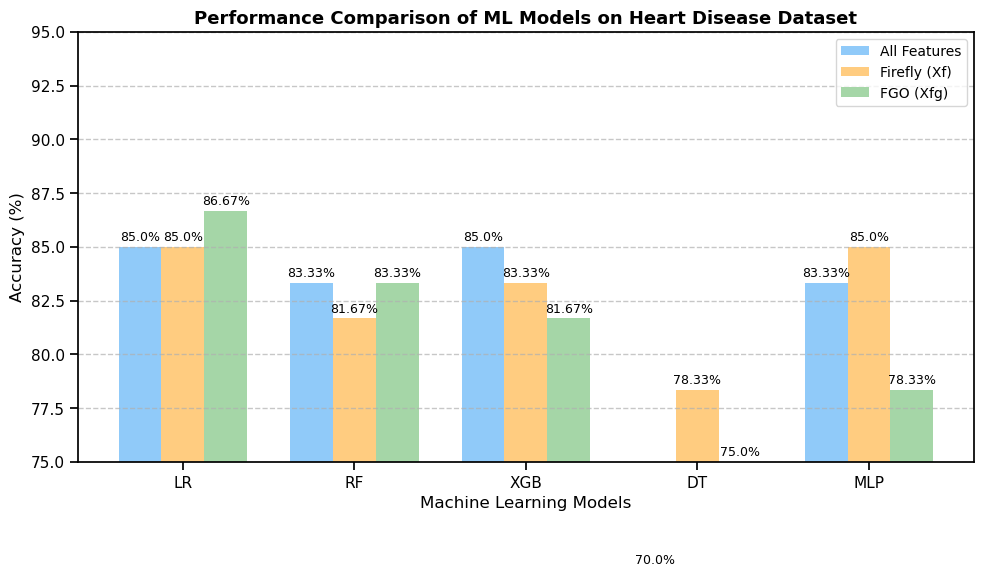

In [95]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you already ran previous code and have "all_results" DataFrame:
# rows = ['All', 'Firefly', 'FGO']
# columns = ['LR', 'RF', 'XGB', 'DT', 'MLP']

# === Prepare data ===
labels = all_results.columns  # Model names
x = np.arange(len(labels))    # model indices
width = 0.25                  # bar width

# Extract accuracy values
acc_all = list(all_results.loc['All'])
acc_fa  = list(all_results.loc['Firefly'])
acc_fgo = list(all_results.loc['FGO'])

# === Plot grouped bars ===
plt.figure(figsize=(10, 6))
plt.bar(x - width, acc_all, width, label='All Features', color='#90CAF9')
plt.bar(x, acc_fa, width, label='Firefly (Xf)', color='#FFCC80')
plt.bar(x + width, acc_fgo, width, label='FGO (Xfg)', color='#A5D6A7')

# === Annotate each bar with accuracy value ===
for i in range(len(x)):
    plt.text(x[i] - width, acc_all[i] + 0.3, f"{acc_all[i]}%", ha='center', fontsize=9)
    plt.text(x[i], acc_fa[i] + 0.3, f"{acc_fa[i]}%", ha='center', fontsize=9)
    plt.text(x[i] + width, acc_fgo[i] + 0.3, f"{acc_fgo[i]}%", ha='center', fontsize=9)

# === Labels and layout ===
plt.xticks(x, labels, fontsize=11)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.xlabel('Machine Learning Models', fontsize=12)
plt.title('Performance Comparison of ML Models on Heart Disease Dataset', fontsize=13, fontweight='bold')
plt.ylim([75, 95])
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Logistic Regression : 86.67%
Random Forest       : 83.33%
XGBoost             : 81.67%
Decision Tree       : 75.0%
MLP                 : 78.33%

✅ Best Model: Logistic Regression
🎯 Best Accuracy: 86.67 %


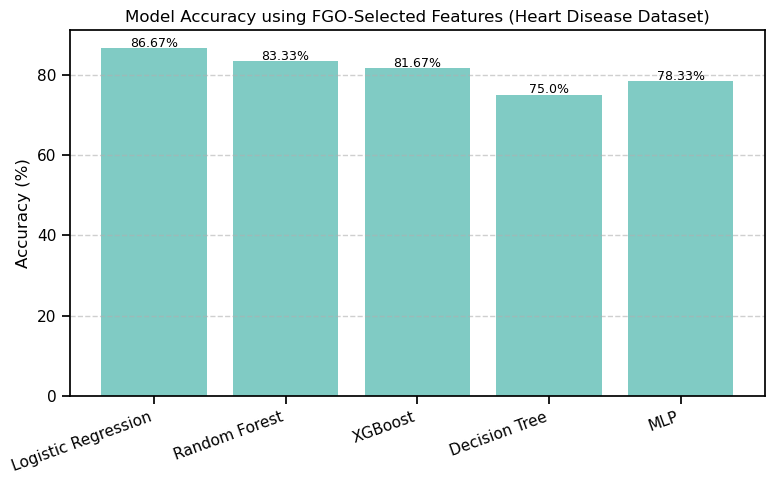

In [96]:
# === FGO-only Evaluation on UCI Cleveland Heart Disease Dataset ===
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

# === Load dataset ===
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
col_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
             "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(url, names=col_names)

# Clean data
df.replace('?', np.nan, inplace=True)
df = df.dropna()
df = df.apply(pd.to_numeric)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

# === Use only FGO-selected features ===
Xfg = df[['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]
y = df['target']

# === Split dataset (80% train / 20% test) ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(Xfg)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=0, stratify=y
)

# === Initialize models ===
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=0)
}

# === Evaluate models ===
acc_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = round(accuracy_score(y_test, y_pred) * 100, 2)
    acc_results[name] = acc
    print(f"{name:20s}: {acc}%")

# === Find best model ===
best_model = max(acc_results, key=acc_results.get)
best_acc = acc_results[best_model]
print("\n✅ Best Model:", best_model)
print("🎯 Best Accuracy:", best_acc, "%")

# === Optional: Plot results ===
plt.figure(figsize=(8, 5))
plt.bar(acc_results.keys(), acc_results.values(), color="#80CBC4")
plt.xticks(rotation=20, ha='right')
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy using FGO-Selected Features (Heart Disease Dataset)")
plt.grid(axis='y', linestyle='--', alpha=0.6)
for i, v in enumerate(acc_results.values()):
    plt.text(i, v + 0.3, f"{v}%", ha='center', fontsize=9)
plt.tight_layout()
plt.show()


# Cross Validation


=== 10-Fold CV Mean Accuracy for All Features ===
      LR: 83.51%
      RF: 82.86%
     XGB: 80.86%
      DT: 70.38%
     MLP: 78.82%
SoftVote: 84.2%
HardVote: 83.52%

=== 10-Fold CV Mean Accuracy for Firefly (Xf) Features ===
      LR: 84.84%
      RF: 80.14%
     XGB: 80.82%
      DT: 75.41%
     MLP: 81.53%
SoftVote: 84.51%
HardVote: 84.16%

=== 10-Fold CV Mean Accuracy for FGO (Xfg) Features ===
      LR: 85.2%
      RF: 79.82%
     XGB: 76.44%
      DT: 71.75%
     MLP: 80.1%
SoftVote: 83.84%
HardVote: 83.16%


=== Summary Table (10-Fold Mean Accuracy %) ===
            LR     RF    XGB     DT    MLP  SoftVote  HardVote
All      83.51  82.86  80.86  70.38  78.82     84.20     83.52
Firefly  84.84  80.14  80.82  75.41  81.53     84.51     84.16
FGO      85.20  79.82  76.44  71.75  80.10     83.84     83.16


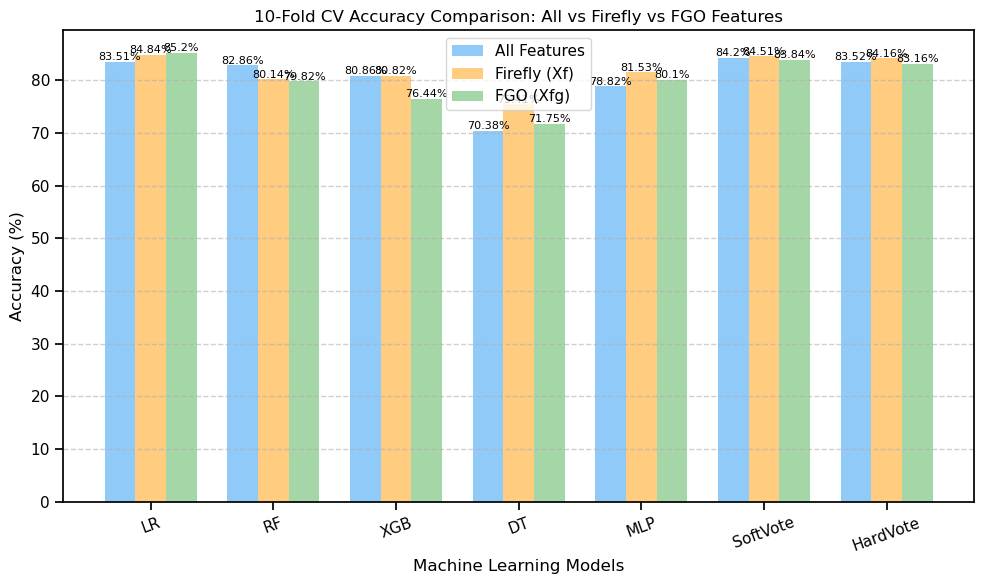

In [101]:
# === 10-Fold Cross-Validation: All vs Firefly vs FGO + Voting Ensemble Comparison ===
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

# === Load dataset ===
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
col_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
             "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(url, names=col_names)

# Clean data
df.replace('?', np.nan, inplace=True)
df = df.dropna()
df = df.apply(pd.to_numeric)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

# === Feature sets ===
X_all = df.drop('target', axis=1)
Xf = df[['age', 'sex', 'cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]   # Firefly
Xfg = df[['cp', 'chol', 'fbs', 'restecg', 'exang', 'oldpeak', 'ca', 'thal']]                # FGO
y = df['target']

# === Models ===
lr = LogisticRegression(max_iter=500)
rf = RandomForestClassifier(n_estimators=200, random_state=0)
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0)
dt = DecisionTreeClassifier(random_state=0)
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=0)
ada = AdaBoostClassifier(random_state=0)

# Voting classifiers
soft_vote = VotingClassifier(
    estimators=[('lr', lr), ('rf', rf), ('ada', ada)], voting='soft'
)
hard_vote = VotingClassifier(
    estimators=[('lr', lr), ('rf', rf), ('ada', ada)], voting='hard'
)

models = {
    "LR": lr,
    "RF": rf,
    "XGB": xgb,
    "DT": dt,
    "MLP": mlp,
    "SoftVote": soft_vote,
    "HardVote": hard_vote
}

# === CV Setup ===
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
scaler = StandardScaler()

def evaluate_cv(X, y, label):
    X_scaled = scaler.fit_transform(X)
    print(f"\n=== 10-Fold CV Mean Accuracy for {label} ===")
    results = {}
    for name, model in models.items():
        scores = cross_val_score(model, X_scaled, y, cv=cv, scoring='accuracy')
        mean_acc = round(scores.mean() * 100, 2)
        results[name] = mean_acc
        print(f"{name:>8s}: {mean_acc}%")
    return results

# === Evaluate on all 3 feature sets ===
res_all = evaluate_cv(X_all, y, "All Features")
res_fa  = evaluate_cv(Xf, y, "Firefly (Xf) Features")
res_fgo = evaluate_cv(Xfg, y, "FGO (Xfg) Features")

# === Combine results ===
summary = pd.DataFrame([res_all, res_fa, res_fgo], index=["All", "Firefly", "FGO"])
print("\n\n=== Summary Table (10-Fold Mean Accuracy %) ===")
print(summary)

# === Plot Accuracy Comparison ===
plt.figure(figsize=(10, 6))
x = np.arange(len(models))
width = 0.25

plt.bar(x - width, summary.loc['All'], width, label='All Features', color='#90CAF9')
plt.bar(x, summary.loc['Firefly'], width, label='Firefly (Xf)', color='#FFCC80')
plt.bar(x + width, summary.loc['FGO'], width, label='FGO (Xfg)', color='#A5D6A7')

# Add text labels
for i in range(len(x)):
    plt.text(x[i] - width, summary.loc['All'][i] + 0.3, f"{summary.loc['All'][i]}%", ha='center', fontsize=8)
    plt.text(x[i], summary.loc['Firefly'][i] + 0.3, f"{summary.loc['Firefly'][i]}%", ha='center', fontsize=8)
    plt.text(x[i] + width, summary.loc['FGO'][i] + 0.3, f"{summary.loc['FGO'][i]}%", ha='center', fontsize=8)

plt.xticks(x, models.keys(), rotation=20)
plt.ylabel('Accuracy (%)')
plt.xlabel('Machine Learning Models')
plt.title('10-Fold CV Accuracy Comparison: All vs Firefly vs FGO Features')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


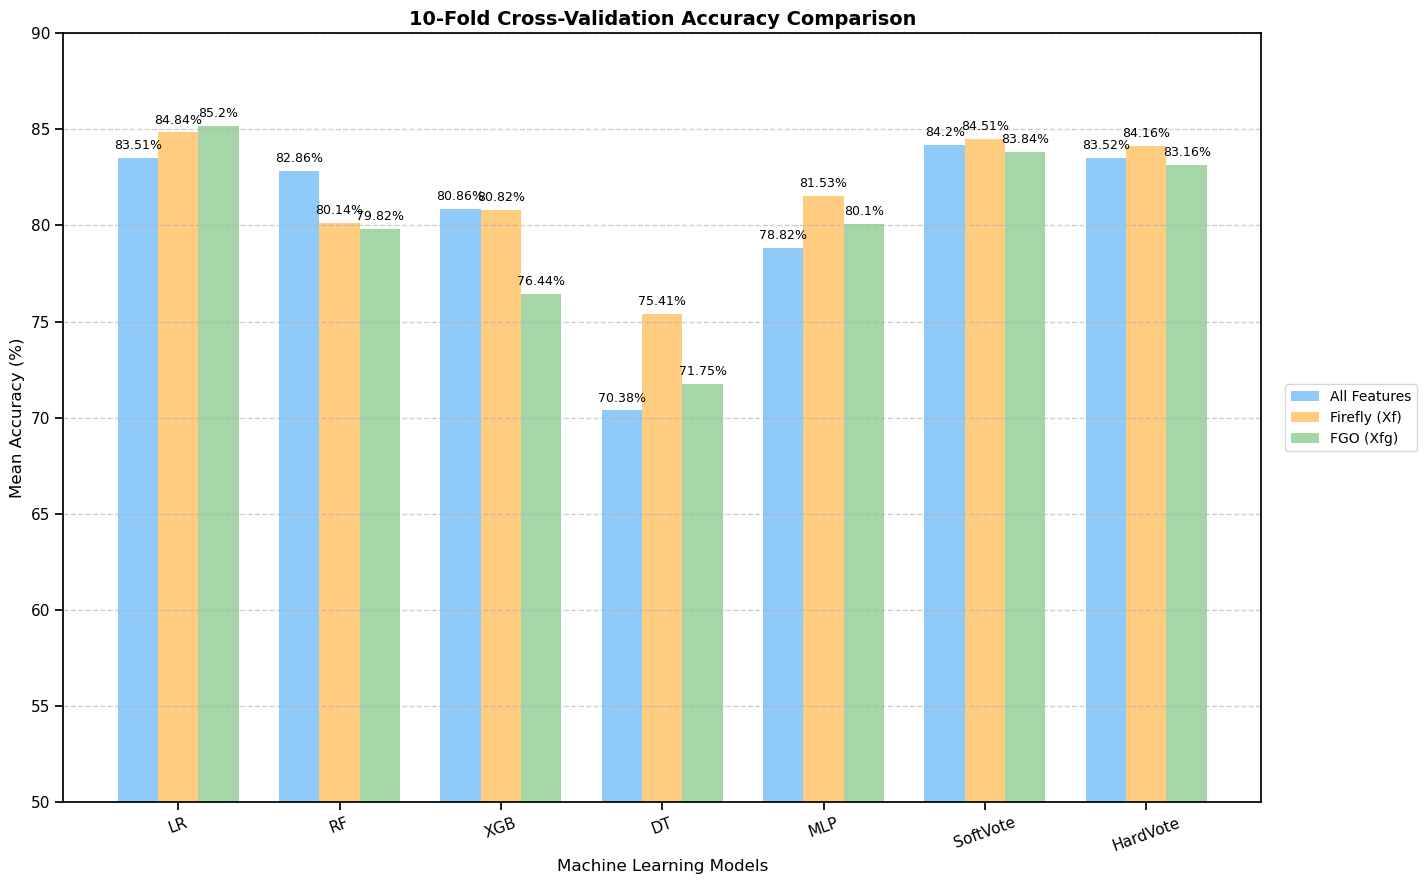

In [106]:
plt.figure(figsize=(17, 9))
x = np.arange(len(models))
width = 0.25

# Bar groups
bars_all = plt.bar(x - width, summary.loc['All'], width, label='All Features', color='#90CAF9')
bars_fa  = plt.bar(x, summary.loc['Firefly'], width, label='Firefly (Xf)', color='#FFCC80')
bars_fgo = plt.bar(x + width, summary.loc['FGO'], width, label='FGO (Xfg)', color='#A5D6A7')

# Add text labels above bars
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.3, f'{height}%', 
                 ha='center', va='bottom', fontsize=9)

add_labels(bars_all)
add_labels(bars_fa)
add_labels(bars_fgo)

# Axis settings
plt.xticks(x, models.keys(), rotation=20)
plt.ylabel('Mean Accuracy (%)', fontsize=12)
plt.xlabel('Machine Learning Models', fontsize=12)
plt.title('10-Fold Cross-Validation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylim([50, 90])
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Move legend outside the plot area (right side)
plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0, fontsize=10)

# Adjust layout to fit everything
plt.tight_layout(rect=[0, 0, 0.85, 1])  # leave space on right for legend
plt.show()